# 28 - Embedding cosine vs ECFP4 Tanimoto, stratified by pocket similarity

Notebook 24 reports Spearman(ligand-embedding cosine, ECFP4 Tanimoto)
pooled across **all** unique ligand-code pairs, and the manuscript
reads a moderate rho there as evidence of pocket-aware ligand
encoding. But nothing in that analysis conditions on pocket
similarity - the inference is suggestive, not tested. If ligand
embeddings really are pocket-conditioned, the chemistry-vs-embedding
relationship should behave differently for ligands bound to similar
pockets than for ligands bound to dissimilar ones; if it looks
identical in every stratum, pocket-conditioning isn't actually doing
anything to that relationship.

This notebook reuses notebook 24's unique-ligand-code-pair machinery
and adds a **pocket structural similarity** column, computed the same
way as notebook 22: an alignment-free USRCAT-style shape descriptor
per pocket, exact pairwise over every supporting instance pair, then
averaged per unique ligand-code pair exactly like ligand-embedding
cosine already is.

**Why USRCAT and not pocket-embedding cosine as the pocket-similarity
signal:** pocket and ligand embeddings are trained jointly in the same
space, so using the model's own pocket embedding to define "similar
pockets" would be circular - any correlation found would partly just
be the model agreeing with itself. USRCAT is computed directly from
pocket atom coordinates and is independent of the model entirely
(notebook 22 already shows pocket-embedding cosine tracks USRCAT only
weakly across arbitrary pocket pairs, so the two are not
interchangeable anyway).

Three analyses, each per individual dataset and on the pooled,
cross-dataset-deduplicated combination, average embedding only
(distinct-code pairs only throughout - self pairs sit at Tanimoto = 1
by construction and would swamp every stratum):

1. **Baseline check** - Spearman(Tanimoto, mean cosine), reproducing
   notebook 24's own number as a sanity check before stratifying.
2. **Pocket-similarity quartiles** - the same correlation recomputed
   within each quartile of mean pocket USRCAT similarity.
3. **Partial correlation** - rank-based partial Spearman of ligand
   cosine vs pocket similarity controlling for Tanimoto (and the
   reverse), plus a version additionally controlling for pocket-size
   similarity.

Regenerate via
`scripts/build_embedding_vs_tanimoto_pocket_stratified_notebook.py`.

## Setup

In [1]:
import time
from pathlib import Path

import h5py
import lmdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.stats import pearsonr, spearmanr, rankdata

from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

PROJECT = Path.cwd().parent / 'DATA' / 'natural_ligands'
MOLS_DIR = PROJECT / 'RESULTS' / 'mols'
POCKETS_DIR = PROJECT / 'RESULTS' / 'pockets'
CCD_MANIFEST = (PROJECT / 'RESULTS' /
                'components_pub_unimol_manifest.tsv')
OUT_DIR = PROJECT / 'RESULTS' / 'embedding_vs_tanimoto_pocket_stratified'
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = ['coach420', 'scpdb', 'pdbbind2020', 'holo4k']
N_FOLDS = 6
EMB_DIM = 128
FP_RADIUS, FP_BITS = 2, 2048   # ECFP4
USR_BLOCK = 4000   # row-block size for the chunked pocket-similarity matrix
N_QUANTILES = 4
print('datasets:', DATASETS)

datasets: ['coach420', 'scpdb', 'pdbbind2020', 'holo4k']


## Pocket USRCAT descriptor (identical to notebook 22)

60-d USR-moments-per-element-channel descriptor, built straight from
each dataset's `pocket.lmdb` (no separate pocket manifest needed - each
lmdb record already carries its own `pocket` id string, which is the
same id used in the bound-ligand manifests' `pocket` column, so the
two can be joined directly).

In [2]:
import pickle

def usrcat(elems, coords):
    '''60-d USRCAT-style descriptor (USR moments x {all,C,N,O,S}).'''
    coords = coords.astype(np.float64)
    ctd = coords.mean(0)
    d = np.linalg.norm(coords - ctd, axis=1)
    cst = coords[d.argmin()]
    fct = coords[d.argmax()]
    ftf = coords[np.linalg.norm(coords - fct, axis=1).argmax()]
    refs = (ctd, cst, fct, ftf)
    chans = (np.ones(len(elems), bool), elems == 'C', elems == 'N',
             elems == 'O', elems == 'S')
    out = []
    for ch in chans:
        if ch.sum() == 0:
            out.extend([0.0] * 12)
            continue
        cc = coords[ch]
        for r in refs:
            dd = np.linalg.norm(cc - r, axis=1)
            m1 = dd.mean()
            m2 = dd.std()
            m3 = np.cbrt(np.mean((dd - m1) ** 3))
            out.extend([m1, m2, m3])
    return np.asarray(out, np.float64)

def load_pocket_descriptors(ds):
    '''pocket id (str) -> (60-d USRCAT descriptor, n_atoms), for one dataset.'''
    cands = [POCKETS_DIR / f'{ds}_pocket.lmdb',
             POCKETS_DIR / ds / 'pocket.lmdb']
    p = next(c for c in cands if c.exists())
    env = lmdb.open(str(p), subdir=False, readonly=True, lock=False,
                    readahead=False)
    out = {}
    with env.begin() as t:
        cur = t.cursor()
        for _, v in cur:
            rec = pickle.loads(v)
            el = np.asarray(rec['pocket_atoms'])
            if len(el) < 4:
                continue
            co = np.asarray(rec['pocket_coordinates'], np.float64).reshape(-1, 3)
            out[rec['pocket']] = (usrcat(el, co), len(el))
    env.close()
    return out

## Load embeddings + ECFP4 fingerprints + pocket descriptors

Same loader as notebook 24, extended to also keep the `pocket` id
column and to require a pocket USRCAT descriptor (dropping the small
number of instances whose pocket has fewer than 4 atoms, matching
notebook 22) alongside the existing ECFP4-validity requirement.

In [3]:
ccd = pd.read_csv(CCD_MANIFEST, sep='\t', dtype=str)
code_to_smi = dict(zip(ccd['identifier'], ccd['smiles']))

_fp_cache = {}
def fp_for_code(c):
    if c in _fp_cache:
        return _fp_cache[c]
    smi = code_to_smi.get(c, '')
    m = Chem.MolFromSmiles(smi) if smi else None
    fp = None if m is None else AllChem.GetMorganFingerprintAsBitVect(
        m, FP_RADIUS, FP_BITS)
    _fp_cache[c] = fp
    return fp

def load_dataset(ds):
    with h5py.File(MOLS_DIR / f'bound_{ds}.h5', 'r') as f:
        reps = f['mol_reps'][:]                       # (N, 768)
    n = reps.shape[0]
    emb = reps.reshape(n, N_FOLDS, EMB_DIM).astype(np.float32)
    man = pd.read_csv(MOLS_DIR / f'bound_{ds}_manifest.tsv',
                      sep='\t', dtype=str)
    if len(man) != n:
        raise ValueError(f'{ds}: manifest {len(man)} != h5 {n} rows')
    man = man.sort_values(
        'lmdb_key', key=lambda s: s.astype(str)).reset_index(drop=True)
    codes = man['lig_resname'].fillna('').to_numpy()
    pdb_ids = man['pdb_id'].fillna('').to_numpy()
    pockets = man['pocket'].fillna('').to_numpy()
    fps = [fp_for_code(c) for c in codes]
    pdesc = load_pocket_descriptors(ds)
    keep = np.array([fp is not None and pk in pdesc
                     for fp, pk in zip(fps, pockets)])
    desc = np.stack([pdesc[pk][0] for pk in pockets[keep]])
    psize = np.array([pdesc[pk][1] for pk in pockets[keep]], dtype=np.float64)
    return {'emb': emb[keep], 'codes': codes[keep], 'pdb_id': pdb_ids[keep],
            'fps': [fp for fp, k in zip(fps, keep) if k],
            'pocket_desc': desc, 'pocket_size': psize,
            'n_total': n, 'n_kept': int(keep.sum())}

data = {}
rows = []
for ds in DATASETS:
    d = load_dataset(ds)
    data[ds] = d
    rows.append({'dataset': ds, 'n_mols': d['n_total'],
                 'with_fp_and_pocket': d['n_kept'],
                 'coverage': d['n_kept'] / d['n_total'],
                 'unique_codes': len(set(d['codes']))})
cover = pd.DataFrame(rows)
cover['coverage'] = (cover['coverage'] * 100).round(1)
print(cover.to_string(index=False))

    dataset  n_mols  with_fp_and_pocket  coverage  unique_codes
   coach420     335                 330      98.5           222
      scpdb    4967                4957      99.8          1684
pdbbind2020    5313                5305      99.8          3893
     holo4k    6690                6599      98.6          1515


## Pool datasets + cross-dataset dedup

Identical to notebook 24, with the pocket descriptor and pocket-size
arrays carried through the same dedup mask.

In [4]:
frames = []
for ds in DATASETS:
    d = data[ds]
    frames.append(pd.DataFrame({'dataset': ds, 'pdb_id': d['pdb_id'],
                                'code': d['codes'],
                                'row': np.arange(len(d['codes']))}))
pooled_man = pd.concat(frames, ignore_index=True)

priority = {ds: i for i, ds in enumerate(DATASETS)}
pooled_man['prio'] = pooled_man['dataset'].map(priority)
chosen = pooled_man.groupby(['pdb_id', 'code'])['prio'].transform('min')
keep_mask = (pooled_man['prio'] == chosen).to_numpy()

emb_pooled_all = np.concatenate([data[ds]['emb'] for ds in DATASETS], axis=0)
fps_pooled_all = sum((data[ds]['fps'] for ds in DATASETS), [])
desc_pooled_all = np.concatenate([data[ds]['pocket_desc'] for ds in DATASETS], axis=0)
size_pooled_all = np.concatenate([data[ds]['pocket_size'] for ds in DATASETS], axis=0)
codes_pooled_all = pooled_man['code'].to_numpy()

emb_pooled = emb_pooled_all[keep_mask]
codes_pooled = codes_pooled_all[keep_mask]
fps_pooled = [fp for fp, k in zip(fps_pooled_all, keep_mask) if k]
desc_pooled = desc_pooled_all[keep_mask]
size_pooled = size_pooled_all[keep_mask]

print(f'pooled: {len(pooled_man):,} rows -> {keep_mask.sum():,} after '
      f'cross-dataset dedup ({(~keep_mask).sum():,} dropped, '
      f'{len(set(codes_pooled)):,} unique codes)')

SCOPES = {ds: {'codes': data[ds]['codes'], 'fps': data[ds]['fps'],
              'emb': data[ds]['emb'], 'desc': data[ds]['pocket_desc'],
              'size': data[ds]['pocket_size']} for ds in DATASETS}
SCOPES['pooled'] = {'codes': codes_pooled, 'fps': fps_pooled,
                    'emb': emb_pooled, 'desc': desc_pooled,
                    'size': size_pooled}
print('\nscopes:', {k: len(v['codes']) for k, v in SCOPES.items()})

pooled: 17,191 rows -> 15,533 after cross-dataset dedup (1,658 dropped, 5,928 unique codes)

scopes: {'coach420': 330, 'scpdb': 4957, 'pdbbind2020': 5305, 'holo4k': 6599, 'pooled': 15533}


## Helper functions

- `full_tanimoto_matrix` - exact pairwise ECFP4 Tanimoto over unique
  ligand codes (same as notebook 24).
- `full_usr_sim_matrix` - the all-pairs analogue of notebook 22's
  sampled USR similarity, computed exactly over every instance pair.
  Built chunked (row-blocks of `USR_BLOCK`) via `scipy.spatial.distance
.cdist`
  so peak memory stays bounded regardless of corpus size (the pooled
  scope has ~17k instances - a naive per-pair array would need tens of
  GB, which is exactly why notebook 22 sampled instead of computing all
  pairs; chunking the full N x N matrix keeps this exact).
- `full_size_sim_matrix` - pocket-size similarity `-|n_a - n_b|`, the
  confound notebook 22 flags for any alignment-free structural
  descriptor.
- `unique_pair_table` - the nb24 core, generalised to also aggregate
  mean pocket-USRCAT-similarity and mean pocket-size-similarity per
  unique ligand-code pair, alongside mean embedding cosine.
- `partial_spearman` - rank-transforms every variable, then computes
  the Pearson correlation of `x` and `y` after regressing out an
  arbitrary set of covariates (least squares on ranks). This is the
  standard way to get a partial *Spearman* correlation, and generalises
  beyond the textbook two-covariate formula to control for more than
  one variable (here: Tanimoto, and optionally pocket-size similarity
  too) at once.

In [5]:
def unit_rows(M):
    nrm = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.clip(nrm, 1e-12, None)

def full_tanimoto_matrix(fps):
    n = len(fps)
    mat = np.ones((n, n), dtype=np.float32)
    for i in range(n - 1):
        sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps[i + 1:])
        mat[i, i + 1:] = sims
        mat[i + 1:, i] = sims
    return mat

def full_usr_sim_matrix(D, block=USR_BLOCK):
    n = D.shape[0]
    ndim = D.shape[1]
    out = np.empty((n, n), dtype=np.float32)
    for s in range(0, n, block):
        e = min(s + block, n)
        d = cdist(D[s:e], D, metric='cityblock') / ndim
        out[s:e] = (1.0 / (1.0 + d)).astype(np.float32)
    return out

def full_size_sim_matrix(sz):
    sz = sz.astype(np.float64)
    return -np.abs(sz[:, None] - sz[None, :]).astype(np.float32)

def factorize_codes(codes):
    code_idx, uniq_codes = pd.factorize(codes, sort=True)
    return code_idx.astype(np.int32), np.asarray(uniq_codes)

def unique_pair_table(code_idx, n_codes, emb, tan_mat, usr_mat, size_mat,
                      uniq_codes):
    E = unit_rows(emb.mean(axis=1))
    cos_full = (E @ E.T).astype(np.float32)
    iu = np.triu_indices(E.shape[0], k=1)
    df = pd.DataFrame({
        'key': None,
        'cos': cos_full[iu],
        'usr': usr_mat[iu],
        'size_sim': size_mat[iu],
    })
    del cos_full
    ci, cj = code_idx[iu[0]], code_idx[iu[1]]
    lo = np.minimum(ci, cj); hi = np.maximum(ci, cj)
    df['key'] = lo.astype(np.int64) * n_codes + hi.astype(np.int64)
    g = df.groupby('key').agg(
        mean_cos=('cos', 'mean'), std_cos=('cos', 'std'),
        mean_usr=('usr', 'mean'), mean_size_sim=('size_sim', 'mean'),
        count=('cos', 'count'))
    lo_g = (g.index // n_codes).to_numpy()
    hi_g = (g.index % n_codes).to_numpy()
    n_g = g['count'].to_numpy()
    return pd.DataFrame({
        'code_a': uniq_codes[lo_g], 'code_b': uniq_codes[hi_g],
        'is_self': lo_g == hi_g,
        'n_instance_pairs': n_g,
        'mean_cos': g['mean_cos'].to_numpy(),
        'sem_cos': (g['std_cos'] / np.sqrt(n_g)).to_numpy(),
        'mean_pocket_sim': g['mean_usr'].to_numpy(),
        'mean_size_sim': g['mean_size_sim'].to_numpy(),
        'tanimoto': tan_mat[lo_g, hi_g],
    })

def partial_spearman(x, y, covariates):
    xr = rankdata(x); yr = rankdata(y)
    Z = np.column_stack([rankdata(c) for c in covariates])
    Z1 = np.column_stack([np.ones(len(x)), Z])
    xr_res = xr - Z1 @ np.linalg.lstsq(Z1, xr, rcond=None)[0]
    yr_res = yr - Z1 @ np.linalg.lstsq(Z1, yr, rcond=None)[0]
    return pearsonr(xr_res, yr_res).statistic

## Compute unique-pair tables (per scope, average embedding)

Per scope: the Tanimoto, pocket-USRCAT-similarity and pocket-size-
similarity matrices are each built once over the scope's unique codes
/ instances, then joined into the same unique-ligand-code-pair table
as notebook 24's `mean_cos`. Self pairs are kept in the table (for
completeness) but excluded from every analysis below.

In [6]:
pair_tables = {}
for scope, s in SCOPES.items():
    t0 = time.time()
    code_idx, uniq_codes = factorize_codes(s['codes'])
    n_codes = len(uniq_codes)
    code_to_fp = {}
    for c, fp in zip(s['codes'], s['fps']):
        code_to_fp.setdefault(c, fp)
    tan_mat = full_tanimoto_matrix([code_to_fp[c] for c in uniq_codes])
    usr_mat = full_usr_sim_matrix(s['desc'])
    size_mat = full_size_sim_matrix(s['size'])
    tab = unique_pair_table(code_idx, n_codes, s['emb'], tan_mat, usr_mat,
                            size_mat, uniq_codes)
    pair_tables[scope] = tab
    print(f'{scope:12s} n_instances={len(s["codes"]):5d} n_codes={n_codes:5d} '
          f'unique_pairs={len(tab):,}  ({time.time()-t0:.1f}s)')

for scope, tab in pair_tables.items():
    tab.to_csv(OUT_DIR / f'{scope}_unique_pairs_with_pocket_sim.tsv',
              sep='\t', index=False)
print('\nwrote per-scope unique-pair tables to', OUT_DIR)

coach420     n_instances=  330 n_codes=  222 unique_pairs=24,583  (0.0s)


scpdb        n_instances= 4957 n_codes= 1684 unique_pairs=1,417,443  (1.8s)


pdbbind2020  n_instances= 5305 n_codes= 3893 unique_pairs=7,576,311  (5.8s)


holo4k       n_instances= 6599 n_codes= 1515 unique_pairs=1,147,684  (2.6s)


pooled       n_instances=15533 n_codes= 5928 unique_pairs=17,569,089  (29.9s)



wrote per-scope unique-pair tables to /Users/jsutges/Documents/NATURAL_LIGANDS/RESULTS/embedding_vs_tanimoto_pocket_stratified


## 1. Baseline check

Spearman(Tanimoto, mean cosine), distinct-code pairs only - should
reproduce notebook 24's own pooled number before anything is
stratified.

In [7]:
baseline_rows = []
for scope, tab in pair_tables.items():
    dist = tab[~tab['is_self']]
    rho = spearmanr(dist['tanimoto'], dist['mean_cos']).statistic
    baseline_rows.append({'scope': scope, 'n_distinct_pairs': len(dist),
                          'spearman_tanimoto_cos': rho})
baseline = pd.DataFrame(baseline_rows).set_index('scope')
print(baseline.round(3).to_string())

             n_distinct_pairs  spearman_tanimoto_cos
scope                                               
coach420                24531                  0.288
scpdb                 1417086                  0.226
pdbbind2020           7575778                  0.235
holo4k                1146855                  0.270
pooled               17567628                  0.228


## 2. Pocket-similarity quartiles

Within each scope, split distinct-code pairs into quartiles of
`mean_pocket_sim` and recompute Spearman(Tanimoto, mean cosine) in
each quartile separately. If embedding cosine genuinely reflects
pocket-conditioned chemistry, the chemistry-cosine relationship need
not be flat across these quartiles; if every quartile shows the same
rho as the pooled baseline, pocket similarity is not modulating the
relationship the manuscript attributes to it.

In [8]:
quartile_rows = []
for scope, tab in pair_tables.items():
    dist = tab[~tab['is_self']].copy()
    try:
        dist['pocket_q'] = pd.qcut(dist['mean_pocket_sim'], N_QUANTILES,
                                   labels=False, duplicates='drop')
    except ValueError:
        continue
    for q, sub in dist.groupby('pocket_q'):
        if len(sub) <= 10:
            continue
        rho = spearmanr(sub['tanimoto'], sub['mean_cos']).statistic
        quartile_rows.append({
            'scope': scope, 'pocket_quartile': int(q), 'n_pairs': len(sub),
            'pocket_sim_range': (round(float(sub['mean_pocket_sim'].min()), 3),
                                round(float(sub['mean_pocket_sim'].max()), 3)),
            'spearman_tanimoto_cos': rho})
quartile_res = pd.DataFrame(quartile_rows)
quartile_res.to_csv(OUT_DIR / 'pocket_quartile_correlations.tsv',
                    sep='\t', index=False)
print(quartile_res.round(3).to_string(index=False))

      scope  pocket_quartile  n_pairs pocket_sim_range  spearman_tanimoto_cos
   coach420                0     6133   (0.195, 0.374)                  0.240
   coach420                1     6133   (0.374, 0.428)                  0.266
   coach420                2     6132   (0.428, 0.485)                  0.302
   coach420                3     6133   (0.485, 0.933)                  0.344
      scpdb                0   354272   (0.114, 0.318)                  0.170
      scpdb                1   354271   (0.318, 0.367)                  0.218
      scpdb                2   354271   (0.367, 0.419)                  0.248
      scpdb                3   354272   (0.419, 0.902)                  0.256
pdbbind2020                0  1893945   (0.114, 0.322)                  0.169
pdbbind2020                1  1893944   (0.322, 0.372)                  0.216
pdbbind2020                2  1893944   (0.372, 0.431)                  0.245
pdbbind2020                3  1893945   (0.431, 0.996)          

wrote /Users/jsutges/Documents/NATURAL_LIGANDS/RESULTS/embedding_vs_tanimoto_pocket_stratified/fig_pocket_quartile_correlations.png


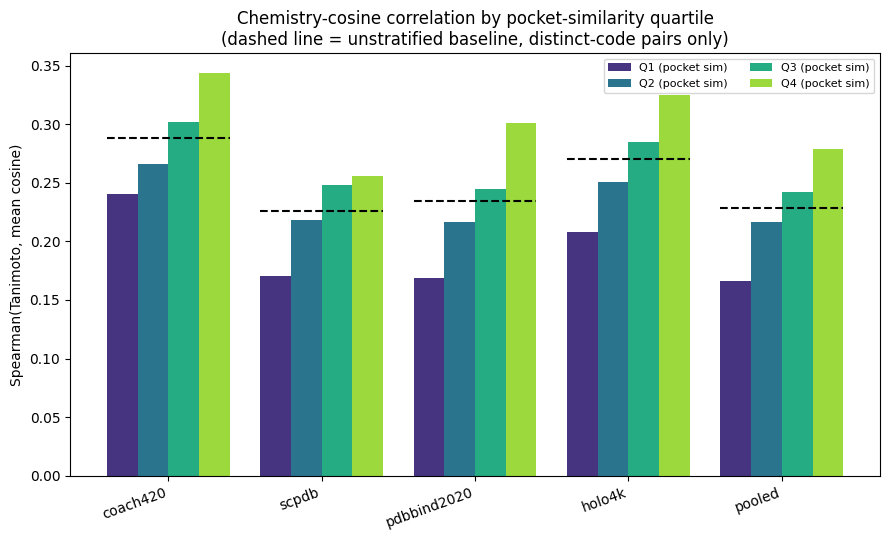

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
scopes = list(SCOPES)
width = 0.8 / N_QUANTILES
colors = plt.cm.viridis(np.linspace(0.15, 0.85, N_QUANTILES))
x0 = np.arange(len(scopes))
for q in range(N_QUANTILES):
    vals = [quartile_res[(quartile_res['scope'] == s) &
                        (quartile_res['pocket_quartile'] == q)]
           ['spearman_tanimoto_cos'] for s in scopes]
    vals = [v.iloc[0] if len(v) else np.nan for v in vals]
    ax.bar(x0 + (q - (N_QUANTILES - 1) / 2) * width, vals, width=width,
          color=colors[q], label=f'Q{q+1} (pocket sim)')
for i, s in enumerate(scopes):
    base = baseline.loc[s, 'spearman_tanimoto_cos']
    ax.plot([i - 0.4, i + 0.4], [base, base], color='k', lw=1.5, ls='--')
ax.axhline(0, color='k', lw=0.6)
ax.set_xticks(x0); ax.set_xticklabels(scopes, rotation=20, ha='right')
ax.set_ylabel('Spearman(Tanimoto, mean cosine)')
ax.set_title('Chemistry-cosine correlation by pocket-similarity quartile\n'
            '(dashed line = unstratified baseline, distinct-code pairs only)')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
out = OUT_DIR / 'fig_pocket_quartile_correlations.png'
fig.savefig(out, dpi=130, bbox_inches='tight')
print('wrote', out)
plt.show()

## 3. Partial correlation

Per scope, distinct-code pairs only:
- `rho(cos, tanimoto)` and `rho(cos, pocket_sim)` - plain (unconditioned)
  Spearman correlations, for reference.
- `rho(cos, pocket_sim | tanimoto)` - does pocket similarity predict
  embedding cosine *beyond* chemical similarity? This is the direct
  test of the manuscript's pocket-aware-encoding claim.
- `rho(cos, tanimoto | pocket_sim)` - the reverse: does chemical
  similarity still predict cosine once pocket similarity is accounted
  for?
- `rho(cos, pocket_sim | tanimoto, size_sim)` - the pocket-similarity
  partial correlation again, now also controlling for pocket-size
  similarity, since USRCAT moments scale with pocket size (notebook
  22's confound).

In [10]:
partial_rows = []
for scope, tab in pair_tables.items():
    dist = tab[~tab['is_self']]
    cos, tan = dist['mean_cos'].to_numpy(), dist['tanimoto'].to_numpy()
    pock, sz = dist['mean_pocket_sim'].to_numpy(), dist['mean_size_sim'].to_numpy()
    partial_rows.append({
        'scope': scope, 'n_pairs': len(dist),
        'rho_cos_tanimoto': spearmanr(cos, tan).statistic,
        'rho_cos_pocketsim': spearmanr(cos, pock).statistic,
        'rho_tanimoto_pocketsim': spearmanr(tan, pock).statistic,
        'rho_cos_pocketsim_given_tanimoto': partial_spearman(cos, pock, [tan]),
        'rho_cos_tanimoto_given_pocketsim': partial_spearman(cos, tan, [pock]),
        'rho_cos_pocketsim_given_tanimoto_size': partial_spearman(
            cos, pock, [tan, sz]),
    })
partial_res = pd.DataFrame(partial_rows).set_index('scope')
partial_res.to_csv(OUT_DIR / 'partial_correlations.tsv', sep='\t')
print(partial_res.round(3).to_string())

              n_pairs  rho_cos_tanimoto  rho_cos_pocketsim  rho_tanimoto_pocketsim  rho_cos_pocketsim_given_tanimoto  rho_cos_tanimoto_given_pocketsim  rho_cos_pocketsim_given_tanimoto_size
scope                                                                                                                                                                                        
coach420        24531             0.288              0.024                   0.029                             0.016                             0.288                                  0.001
scpdb         1417086             0.226              0.059                   0.062                             0.046                             0.223                                  0.027
pdbbind2020   7575778             0.235              0.069                   0.026                             0.065                             0.233                                  0.047
holo4k        1146855             0.270           

wrote /Users/jsutges/Documents/NATURAL_LIGANDS/RESULTS/embedding_vs_tanimoto_pocket_stratified/fig_partial_correlations.png


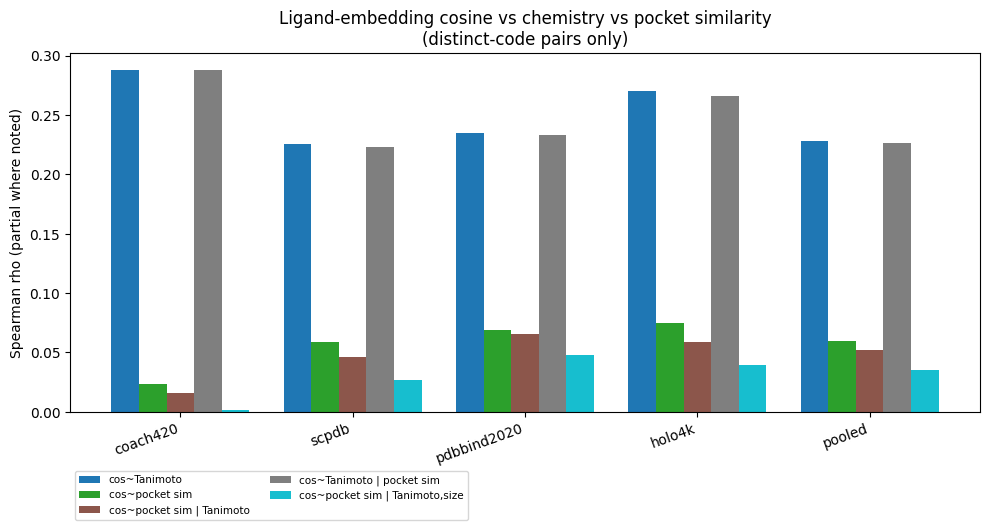

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
cols = ['rho_cos_tanimoto', 'rho_cos_pocketsim',
        'rho_cos_pocketsim_given_tanimoto', 'rho_cos_tanimoto_given_pocketsim',
        'rho_cos_pocketsim_given_tanimoto_size']
labels = ['cos~Tanimoto', 'cos~pocket sim',
         'cos~pocket sim | Tanimoto', 'cos~Tanimoto | pocket sim',
         'cos~pocket sim | Tanimoto,size']
x = np.arange(len(partial_res))
width = 0.8 / len(cols)
colors = plt.cm.tab10(np.linspace(0, 1, len(cols)))
for i, (col, lab) in enumerate(zip(cols, labels)):
    ax.bar(x + (i - (len(cols) - 1) / 2) * width, partial_res[col],
          width=width, color=colors[i], label=lab)
ax.axhline(0, color='k', lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(partial_res.index, rotation=20, ha='right')
ax.set_ylabel('Spearman rho (partial where noted)')
ax.set_title('Ligand-embedding cosine vs chemistry vs pocket similarity\n'
            '(distinct-code pairs only)')
ax.legend(fontsize=7.5, ncol=2, loc='upper left', bbox_to_anchor=(0, -0.15))
fig.tight_layout()
out = OUT_DIR / 'fig_partial_correlations.png'
fig.savefig(out, dpi=130, bbox_inches='tight')
print('wrote', out)
plt.show()

## Takeaways

- **Baseline check** confirms (or flags a discrepancy from) notebook
  24's pooled Spearman(Tanimoto, cosine) before any stratification is
  applied - if these numbers disagree, something about dedup/instance
  coverage differs between the two notebooks (likely the extra
  pocket-descriptor coverage filter here) and should be reconciled
  before reading the rest of this notebook.
- **Quartile panel**: if every pocket-similarity quartile reproduces
  roughly the same chemistry-cosine rho as the dashed baseline, the
  chemistry-cosine relationship notebook 24 reports does not depend on
  pocket similarity - i.e. it is not evidence of pocket-conditioned
  encoding by itself. A quartile pattern (e.g. a stronger or weaker
  rho among pocket-similar pairs) would be the first direct evidence
  either way.
- **Partial correlations** are the sharper test: `cos~pocket sim |
  Tanimoto` asks whether pocket similarity carries information about
  embedding cosine that chemical similarity does not already carry.
  A value near zero means it does not - pocket similarity (as measured
  here, by independent structural descriptor) adds nothing once
  chemistry is accounted for, which would undercut the pocket-aware-
  encoding reading of notebook 24's result. A value clearly away from
  zero, especially if it survives adding the pocket-size control,
  would be the rigorous version of the evidence the manuscript
  currently only asserts.
- None of this should be read as a verdict ahead of actually running
  the notebook on the real data - the point of adding it is to let the
  numbers say which of these two readings holds, rather than inferring
  pocket-awareness from a result that never conditioned on pockets at
  all.